# JSONBench walkthrough

Generate a small travel dataset in memory.

In [1]:
from json_bench.data import generate_travel_dataset

dataset = generate_travel_dataset(
    scale=0.1,
    seed=23,
    reference_date="2025-11-01",
)

## Deploy the databases

Start Docker and run `uv sync --locked` first. BONDI waits for each database to be ready.
Couchbase uses Community Edition with a `travel` bucket. Change the names or ports if needed.

In [2]:
from bondi.deployment import deploy_couchbase, deploy_mongodb

mongo_deployment = deploy_mongodb(name="jsonbench-travel", port=27127)
couchbase_deployment = deploy_couchbase(
    name="jsonbench-travel-cb",
    management_port=18291,
    query_port=18293,
    kv_port=21230,
    bucket="travel",
)
print(mongo_deployment.uri)
print(couchbase_deployment.console_url)

mongodb://127.0.0.1:27127/
http://127.0.0.1:18291/


## Load the same dataset into both databases

Load each collection into MongoDB and Couchbase, preserving document IDs and date strings.
BONDI derives Couchbase keys from the IDs and creates no query indexes.
The default `create` mode requires empty collections. Run cleanup before repeating deployment and loading.

In [3]:
from bondi.couchbase import CouchbaseCollectionRef
from bondi.data import load_documents
from bondi.mongodb import MongoCollectionRef

for name, documents in dataset.items():
    mongo_result = load_documents(
        documents,
        target=mongo_deployment,
        collection=MongoCollectionRef("travel", name),
        mode="replace",
    )
    couchbase_result = load_documents(
        documents,
        target=couchbase_deployment,
        collection=CouchbaseCollectionRef("travel", "_default", name),
        mode="replace",
    )
    print(mongo_result.destinations, couchbase_result.destinations)

{'travel.users': 100} {'travel._default.users': 100}
{'travel.tours': 20} {'travel._default.tours': 20}
{'travel.bookings': 500} {'travel._default.bookings': 500}
{'travel.reviews': 250} {'travel._default.reviews': 250}


## Build Q1–Q8 workloads

Translate all eight templates into one ordered BONDI workload per database.

In [ ]:
from pathlib import Path
from pprint import pprint

from bondi.workload import Workload, WorkloadEntry

from json_bench.queries import load_template, translate_couchbase, translate_mongodb

# Support kernels started in either the repository root or notebooks/.
project_root = Path.cwd()
if not (project_root / "experiments" / "templates").is_dir():
    project_root = project_root.parent

template_dir = project_root / "experiments" / "templates"
templates = [load_template(template_dir / f"q{i}.json") for i in range(1, 9)]

# Change Q4's parameter in memory; keep the saved paper template unchanged.
q4 = templates[3]
q4["operations"]["match"]["itinerary.location"] = dataset["tours"][0]["itinerary"][0]["location"]
print("Q4 location:", q4["operations"]["match"]["itinerary.location"])

mongo_workload = Workload(
    [WorkloadEntry(translate_mongodb(t, database="travel")) for t in templates]
)
couchbase_workload = Workload(
    [WorkloadEntry(translate_couchbase(t, bucket="travel")) for t in templates]
)

for template, mongo_entry, couchbase_entry in zip(
    templates, mongo_workload, couchbase_workload, strict=True
):
    print(template["name"])
    pprint(mongo_entry.query.pipeline)
    print(couchbase_entry.query.statement)

Q4 location: Chapmanchester
Query 1
[{'$group': {'_id': '$tour_id', 'total_revenue': {'$sum': '$total_price'}}}]
SELECT `bookings`.`tour_id` AS `tour_id`, SUM(`bookings`.`total_price`) AS `total_revenue` FROM `bookings` GROUP BY `bookings`.`tour_id`;
Query 2
[{'$unwind': '$travellers'},
 {'$group': {'_id': '$tour_id',
             'avg_age': {'$avg': '$travellers.age'},
             'max_age': {'$max': '$travellers.age'},
             'min_age': {'$min': '$travellers.age'}}}]
SELECT `bookings`.`tour_id` AS `tour_id`, AVG(`__unnest_0`.`age`) AS `avg_age`, MIN(`__unnest_0`.`age`) AS `min_age`, MAX(`__unnest_0`.`age`) AS `max_age` FROM `bookings` UNNEST `bookings`.`travellers` AS `__unnest_0` GROUP BY `bookings`.`tour_id`;
Query 3
[{'$group': {'_id': '$tour_id',
             'avg_grp_size': {'$avg': {'$size': '$travellers'}}}}]
SELECT `bookings`.`tour_id` AS `tour_id`, AVG(ARRAY_LENGTH(`bookings`.`travellers`)) AS `avg_grp_size` FROM `bookings` GROUP BY `bookings`.`tour_id`;
Query 4
[{'$u

## Prepare baseline indexes

Create the corrected JSONBench join indexes in both databases and wait for readiness.
MongoDB already indexes tours._id. Repeat calls reuse matching named indexes; unrelated indexes remain.


In [ ]:
import json

from bondi import IndexSet

from json_bench.indexes import ensure_couchbase_indexes, ensure_mongodb_indexes

index_specs = json.loads((project_root / "experiments" / "indexes.json").read_text())
ensure_mongodb_indexes(mongo_deployment, IndexSet.from_dict(index_specs["mongodb"]))
ensure_couchbase_indexes(couchbase_deployment, IndexSet.from_dict(index_specs["couchbase"]))


## Execute the workloads

Run each query once and retain its documents. Use REQUEST_PLUS to include newly loaded data
in Couchbase. This is a correctness check, not a benchmark.


In [6]:
from bondi.couchbase import CouchbaseExecutor
from bondi.mongodb import MongoExecutor
from couchbase.n1ql import QueryScanConsistency

with MongoExecutor.from_uri(mongo_deployment.uri, timeout_seconds=60) as executor:
    mongo_results = executor.run_workload(mongo_workload, collect_results=True)

with CouchbaseExecutor.from_uri(
    couchbase_deployment.uri,
    username=couchbase_deployment.username,
    password=couchbase_deployment.password,
    timeout_seconds=60,
) as executor:
    couchbase_results = executor.run_workload(
        couchbase_workload,
        collect_results=True,
        query_kwargs={"scan_consistency": QueryScanConsistency.REQUEST_PLUS},
    )

## Compare query results

Compare each query in workload order. Require the same tour groups and aggregate fields,
ignore row order, and allow small floating-point differences.

In [ ]:
from json_bench.validate import compare_results

for template, mongo_result, couchbase_result in zip(
    templates, mongo_results, couchbase_results, strict=True
):
    compare_results(template, mongo_result, couchbase_result)
    print(f"{template['name']}: results match")

Query 1: results match
Query 2: results match
Query 3: results match
Query 4: results match
Query 5: results match
Query 6: results match
Query 7: results match
Query 8: results match


## Generate sustained load

Run MongoDB, then Couchbase, with only one database running at a time.
Use equal explicit weights for Q1–Q8. Each client selects its next query after the previous one finishes.
This short example demonstrates execution; it is not the paper's measurement protocol.

Retain every `LoadResult`, including warm-up, failures and drain expiry. Set `collect_results=False`
to avoid retaining database documents. The same seed reproduces each client's selection prefix,
not identical attempt counts across databases. Both deployments remain stopped after this cell.


In [8]:
from bondi.load import WeightedRandom

QUERY_WEIGHTS = [1, 1, 1, 1, 1, 1, 1, 1]  # Q1–Q8; edit to change the mix.
LOAD_SEED = 23
CLIENTS = 2
WARMUP_SECONDS = 5
MEASUREMENT_SECONDS = 15
QUERY_TIMEOUT_SECONDS = 10
DRAIN_TIMEOUT_SECONDS = 15

assert len(QUERY_WEIGHTS) == len(templates)
load_results = {}  # Backend name -> list of BONDI LoadResult objects.

In [9]:
# Stop both first, including when this cell is run again.
mongo_deployment.stop()
couchbase_deployment.stop()

for backend, deployment, workload, executor_type, credentials in [
    ("mongodb", mongo_deployment, mongo_workload, MongoExecutor, {}),
    (
        "couchbase",
        couchbase_deployment,
        couchbase_workload,
        CouchbaseExecutor,
        {"username": couchbase_deployment.username, "password": couchbase_deployment.password},
    ),
]:
    print(f"Running {backend} with {CLIENTS} clients...", flush=True)
    try:
        deployment.start()
        with executor_type.from_uri(
            deployment.uri,
            **credentials,
            concurrency=CLIENTS,
            timeout_seconds=QUERY_TIMEOUT_SECONDS,
            continue_on_error=True,
        ) as executor:
            load_results[backend] = executor.generate_load(
                workload,
                selection=WeightedRandom(weights=QUERY_WEIGHTS, seed=LOAD_SEED),
                warmup_seconds=WARMUP_SECONDS,
                measurement_seconds=MEASUREMENT_SECONDS,
                drain_timeout_seconds=DRAIN_TIMEOUT_SECONDS,
                collect_results=False,
                return_load_results=True,
            )
        print(f"Retained {len(load_results[backend])} observations.")
    finally:
        deployment.stop()

Running mongodb with 2 clients...
Retained 5182 observations.
Running couchbase with 2 clients...
Retained 406 observations.


## Inspect retained observations

Show per-query outcomes for measurement admissions, including those that finish during draining.
These counts are not throughput. Raw objects remain in `load_results`; the table keeps phase,
timing, client and stop-reason fields for later analysis. `duration` includes health preflight.


In [ ]:
import pandas as pd
from IPython.display import display

load_observations = pd.DataFrame(
    [
        {
            "backend": backend,
            "query": templates[item.workload_position]["name"],
            "attempt_id": item.attempt_id,
            "client_id": item.client_id,
            "phase": item.phase_started,
            "admitted_seconds": item.admitted_seconds,
            "ended_seconds": item.ended_seconds,
            "duration_seconds": item.duration,
            "outcome": item.result.status if item.result is not None else "unresolved",
            "stop_reason": item.stop_reason,
        }
        for backend, observations in load_results.items()
        for item in observations
    ]
)
measurement_observations = load_observations.loc[load_observations["phase"] == "measurement"]
display(
    measurement_observations.groupby(["backend", "query", "outcome"]).size().unstack(fill_value=0)
)
display(load_observations.head())

outcome            success
backend   query           
couchbase Query 1       28
          Query 2       43
          Query 3       35
          Query 4       46
          Query 5       42
          Query 6       32
          Query 7       43
          Query 8       33
mongodb   Query 1      496
          Query 2      474
          Query 3      449
          Query 4      479
          Query 5      460
          Query 6      478
          Query 7      527
          Query 8      466

,backend,query,attempt_id,client_id,phase,admitted_seconds,ended_seconds,duration_seconds,outcome,stop_reason
0,mongodb,Query 2,1,1,warmup,0.000181,0.014370,0.014190,success,None
1,mongodb,Query 7,2,1,warmup,0.014425,0.023604,0.009179,success,None
2,mongodb,Query 1,3,1,warmup,0.023651,0.024944,0.001293,success,None
3,mongodb,Query 6,0,0,warmup,0.000157,0.025530,0.025373,success,None
4,mongodb,Query 1,4,1,warmup,0.024985,0.026225,0.001240,success,None


## Summarise the load runs

Throughput counts successes completed within measurement. Runtime and outcome counts
include drain completions for measurement admissions. Check early termination and unresolved counts.


In [11]:
from dataclasses import asdict

from json_bench.analysis import summarise_load_results

load_summaries = {
    backend: summarise_load_results(
        observations,
        warmup_seconds=WARMUP_SECONDS,
        measurement_seconds=MEASUREMENT_SECONDS,
    )
    for backend, observations in load_results.items()
}
display(pd.DataFrame({backend: asdict(value) for backend, value in load_summaries.items()}).T)

,measurement_seconds,measurement_admissions,successes_within_window,throughput_queries_per_second,mean_runtime_seconds,median_runtime_seconds,success_count,error_count,timeout_count,unresolved_count,early_terminated,stop_reasons
mongodb,15,3829,3827,255.133333,0.00772,0.002132,3829,0,0,0,False,()
couchbase,15,302,300,20.0,0.09814,0.061202,302,0,0,0,False,()


## Prepare per-query analysis

Summarise the retained load results in workload order, excluding warm-up admissions.
Successful runtime samples include drain completions; outcomes also include unresolved attempts.


In [12]:
from IPython.display import display

from json_bench.analysis import analyse_load_results
from json_bench.plotting import plot_query_outcomes, plot_query_runtimes

query_analyses = {
    label: analyse_load_results(
        load_results[backend],
        query_labels=[template["name"] for template in templates],
        warmup_seconds=WARMUP_SECONDS,
        measurement_seconds=MEASUREMENT_SECONDS,
    )
    for backend, label in [("mongodb", "MongoDB"), ("couchbase", "Couchbase")]
}

## Successful query runtime distributions

Compare median and quartile runtimes by query, with 5th–95th percentile whiskers on a log axis.


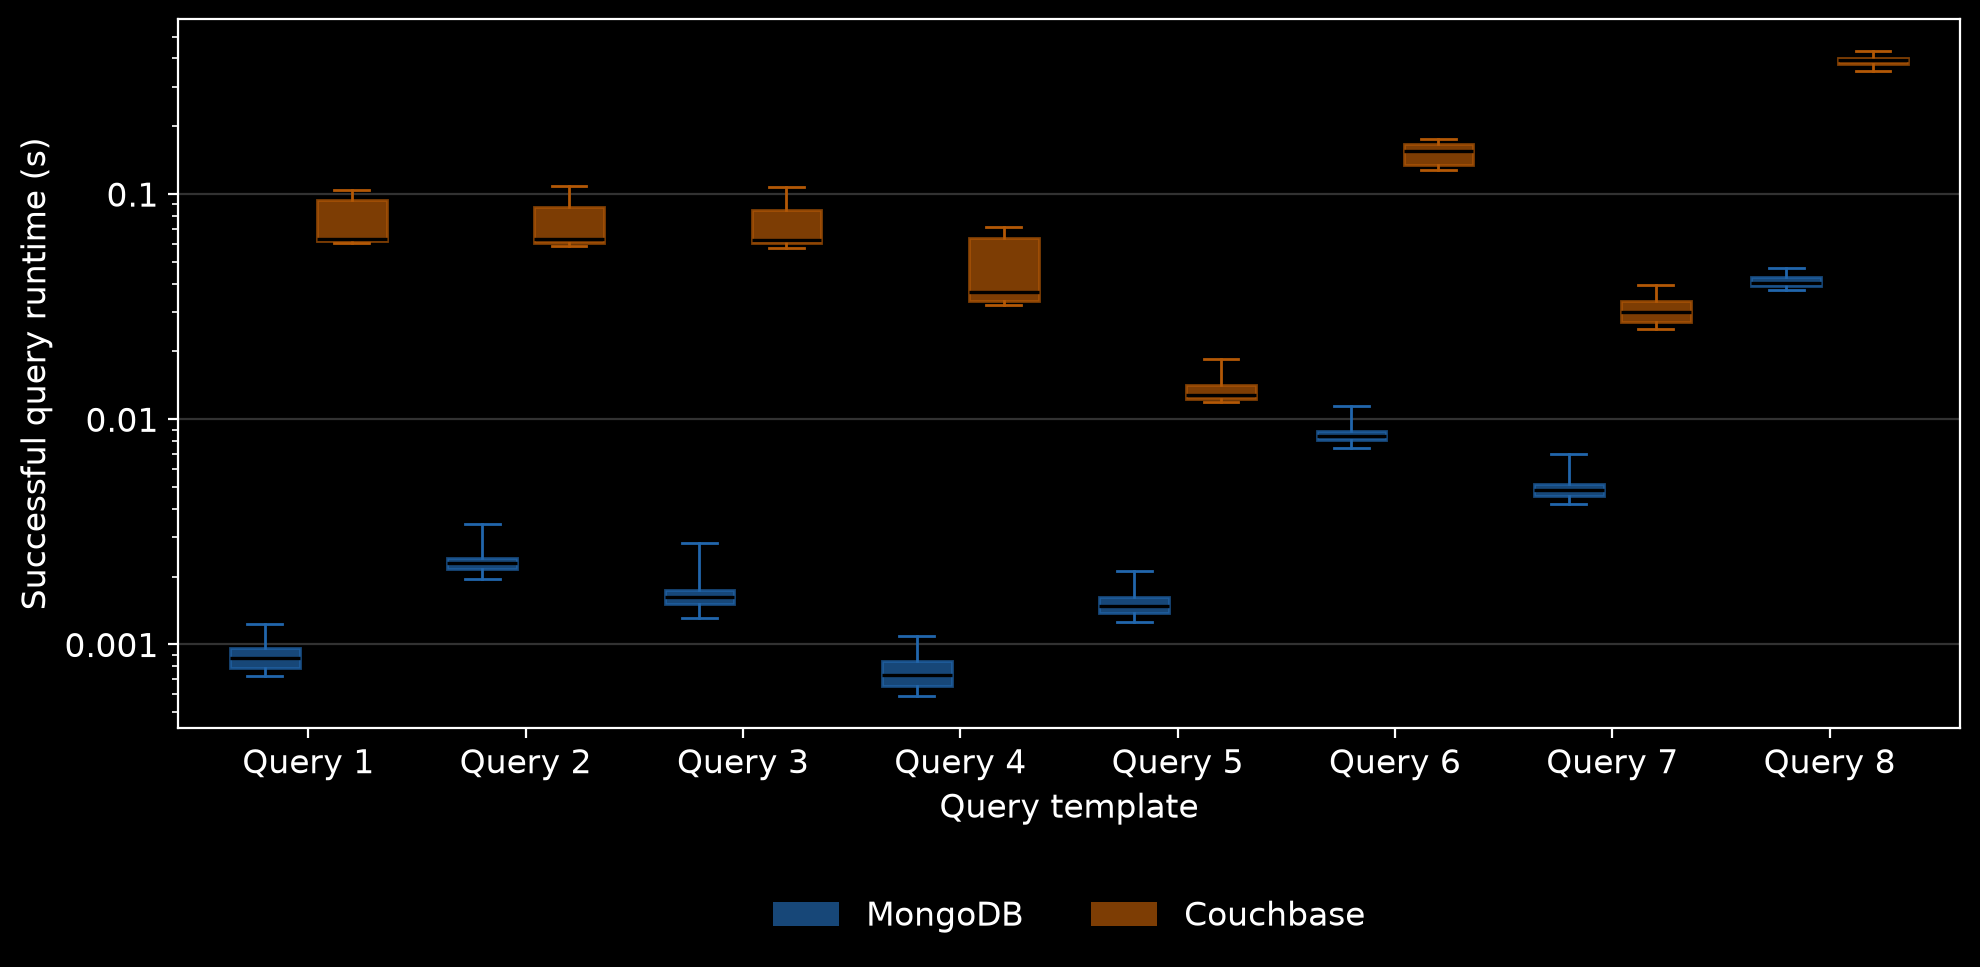

In [13]:
query_runtime_figure = plot_query_runtimes(query_analyses)
display(query_runtime_figure)

## Query outcome counts

Compare absolute success, error, timeout and unresolved counts by query and database.


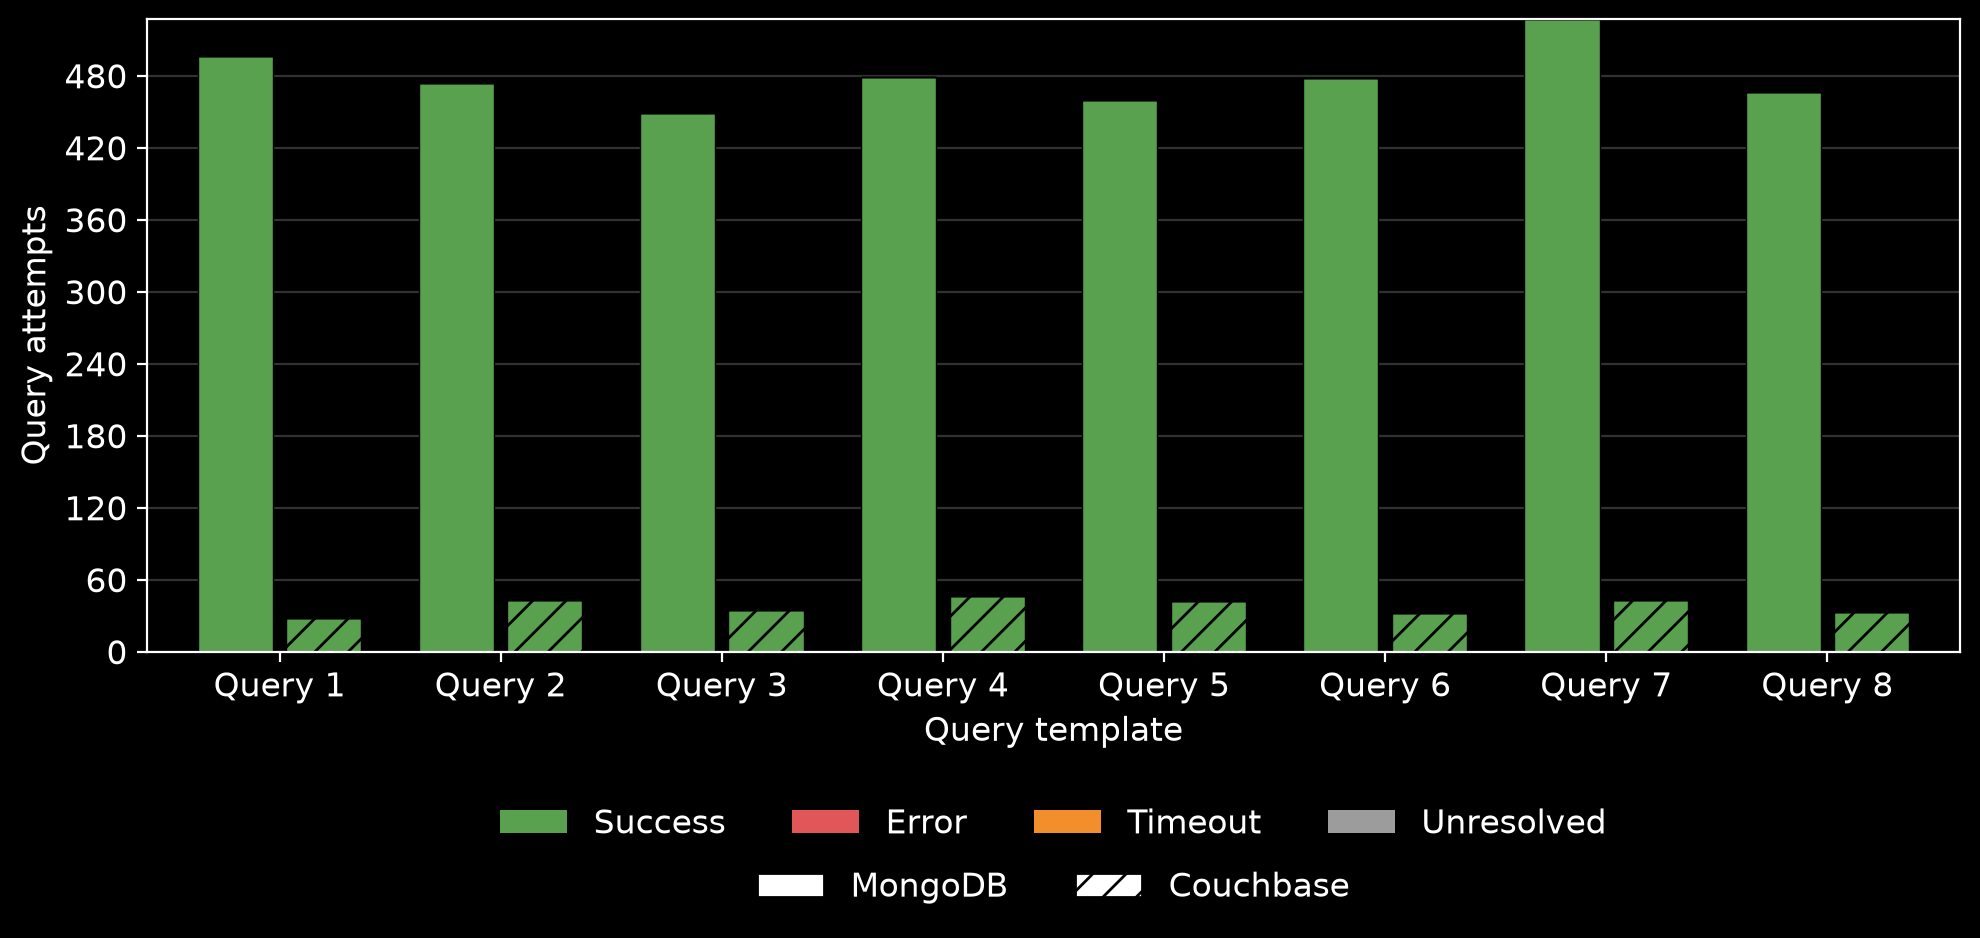

In [14]:
query_outcome_figure = plot_query_outcomes(query_analyses)
display(query_outcome_figure)

## Clean up when finished

Remove both deployments, including their data and saved configuration.

In [15]:
mongo_deployment.stop()
couchbase_deployment.stop()